<a href="https://colab.research.google.com/github/rio-ru001/colab-notebooks-my-project-/blob/main/WANGJINGRU_Dynamic_Health_Insurance_Pricing_via_loT_Wearables_Python_submit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== 大数据处理与动态定价结果样例 ===
   customer_id  age  cleaned_steps  resting_heart_rate  sleep_hours  \
0         1001   53           8149                  68          3.8   
1         1002   39           9454                  73          5.8   
2         1003   32           4407                  60          7.5   
3         1004   45           4198                  60          6.6   
4         1005   43           8804                  66          7.2   
5         1006   47           8242                  70          6.1   
6         1007   35           8126                  74          6.9   
7         1008   35           8366                  83          6.6   
8         1009   48           5799                  78          8.2   
9         1010   48           8080                  70          7.1   

   risk_probability  dynamic_premium  
0              0.89          6973.00  
1              0.85          6745.00  
2              0.71          5367.17  
3              0.99          7543.00  


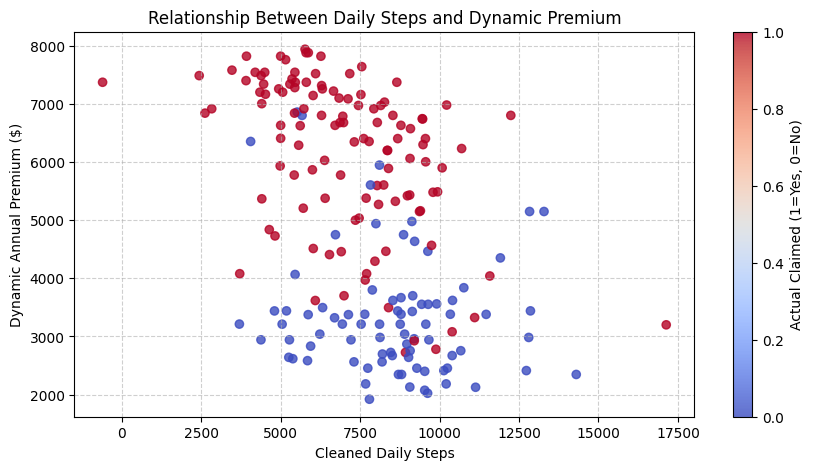

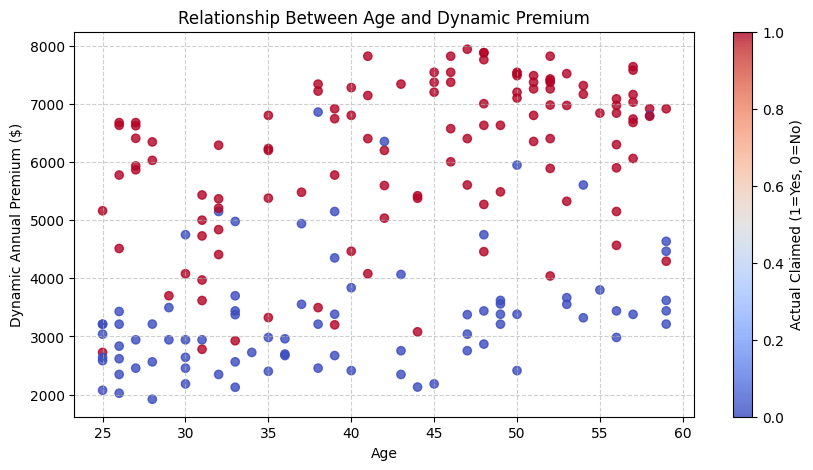

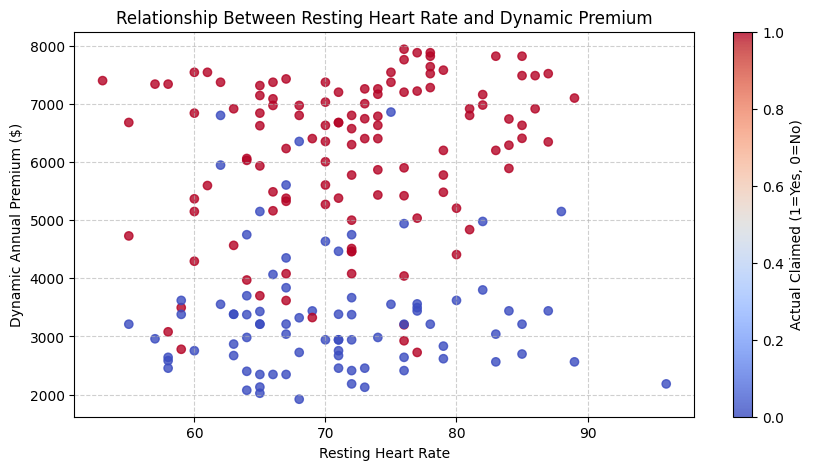

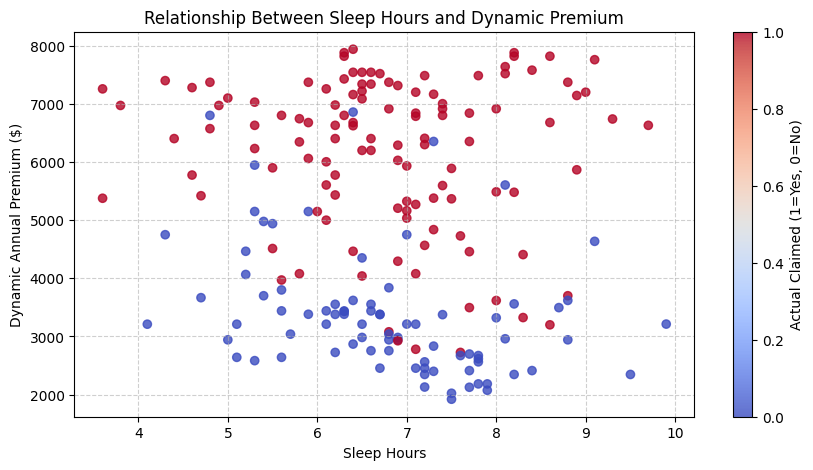

Mean Absolute Error (MAE): 0.2569
Root Mean Squared Error (RMSE): 0.3283
R-squared (R²): 0.5561


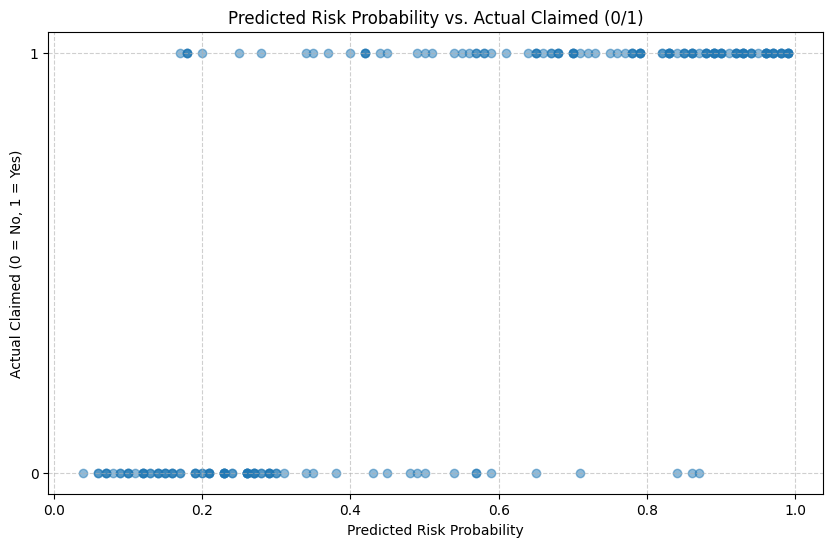

/tmp/ipykernel_554/3257695142.py:163: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')


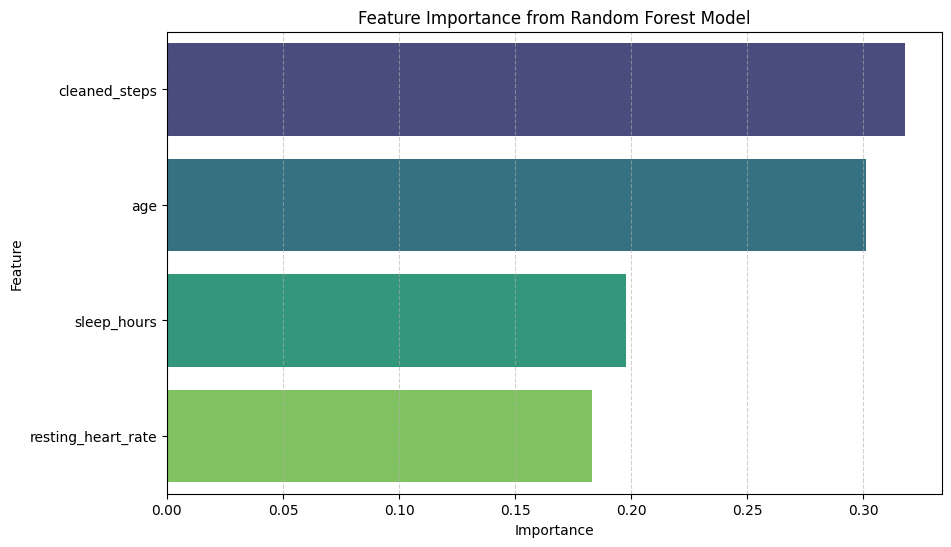

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# 🛠️ Step 1: Simulating a Large-Scale Wearable Dataset (Mock Data Generation)
np.random.seed(42)
n_customers = 200

data = {
    'customer_id': range(1001, 1001 + n_customers),
    'age': np.random.randint(25, 60, size=n_customers),
    'daily_steps': np.random.normal(loc=7500, scale=2500, size=n_customers).astype(int),
    'resting_heart_rate': np.random.normal(loc=72, scale=8, size=n_customers).astype(int),
    'sleep_hours': np.random.normal(loc=6.8, scale=1.2, size=n_customers).round(1),
    # Intentionally injecting a few cheating users (with abnormally high step counts alongside extremely high resting heart rates, defying physiological norms)
    'is_cheating_signal': np.zeros(n_customers)
}

df = pd.DataFrame(data)

# Inject 3 cheating outliers (e.g., using a step shaker)
df.loc[10:12, 'daily_steps'] = 28000
df.loc[10:12, 'resting_heart_rate'] = 85  # Someone who runs over 20,000 steps shouldn't have a resting heart rate this high
df.loc[10:12, 'is_cheating_signal'] = 1

# 🛠️ Step 2: Big Data Anti-Fraud Cleansing (Data Cleaning & Anti-Fraud)
# Rule: If the step count is extremely high (> 20,000) and the resting heart rate is also elevated (> 80), flag it as a data anomaly/cheating and reset the step count to the baseline value.
fraud_mask = (df['daily_steps'] > 20000) & (df['resting_heart_rate'] > 80)
df['data_compromised'] = np.where(fraud_mask, 1, 0)
# Sanitize fraudulent data to prevent pricing model contamination
df['cleaned_steps'] = np.where(fraud_mask, 5000, df['daily_steps'])

# 🛠️ Step 3: Simulate Claim Labels (Generate Claims Ground Truth)
# To simulate real-world health dynamics, individuals who are older, take fewer daily steps, suffer from sleep deprivation, and exhibit an elevated resting heart rate have a higher probability of filing an insurance claim
risk_score = (
    df['age'] * 0.05
    - (df['cleaned_steps'] / 3000)
    + (df['resting_heart_rate'] * 0.04)
    - df['sleep_hours'] * 0.3
)
# Convert to 0 (no claim) or 1 (claim)
p = 1 / (1 + np.exp(-risk_score))
df['claimed'] = np.random.binomial(1, p)

# 🛠️ Step 4: Building a Machine Learning Prediction Model (Predictive Modeling)
features = ['age', 'cleaned_steps', 'resting_heart_rate', 'sleep_hours']
X = df[features]
y = df['claimed']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predicting each person's claim probability (Risk Probability)
df['risk_probability'] = model.predict_proba(X)[:, 1]

# 🛠️ Step 5: Dynamic Premium Pricing Logic (Dynamic Insurance Pricing)
# The base premium is CNY 5,000
base_premium = 5000

# First, calculate an initial adjusted premium based on the risk probability
# Active, low-risk individuals pay lower premiums, while inactive, high-risk ones pay more
initial_adjusted_premium = (base_premium * (0.4 + df['risk_probability'] * 1.2))

# introduce additional premium adjustment factors (Premium Adjustment Factor)
# Defaults to 1, indicating no additional adjustment.
premium_adjustment_factor = pd.Series(1.0, index=df.index)

# The younger you are, the lower the premium (i.e.：age < 35, apply 5% discount)
premium_adjustment_factor = np.where(df['age'] < 35, premium_adjustment_factor * 0.95, premium_adjustment_factor)

# Normal heart rate, lower premiums (i.e.：resting_heart_rate between 60 and 75, apply 5% discount)
premium_adjustment_factor = np.where((df['resting_heart_rate'] >= 60) & (df['resting_heart_rate'] <= 75), premium_adjustment_factor * 0.95, premium_adjustment_factor)

# Get 7–8 hours of sleep, pay less for insurance (apply 5% discount)
premium_adjustment_factor = np.where((df['sleep_hours'] >= 7.0) & (df['sleep_hours'] <= 8.0), premium_adjustment_factor * 0.95, premium_adjustment_factor)

# Combine the initial adjusted premium with additional adjustment factors
df['dynamic_premium'] = (initial_adjusted_premium * premium_adjustment_factor).round(2)

print("=== 大数据处理与动态定价结果样例 ===")
print(df[['customer_id', 'age', 'cleaned_steps', 'resting_heart_rate', 'sleep_hours', 'risk_probability', 'dynamic_premium']].head(10))

# 🛠️ Step 6: Assignment Presentation Data Visualization (Visualization for PPT)
plt.figure(figsize=(10, 5))
plt.scatter(df['cleaned_steps'], df['dynamic_premium'], c=df['claimed'], cmap='coolwarm', alpha=0.8)
plt.colorbar(label='Actual Claimed (1=Yes, 0=No)')
plt.title('Relationship Between Daily Steps and Dynamic Premium')
plt.xlabel('Cleaned Daily Steps')
plt.ylabel('Dynamic Annual Premium ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

plt.figure(figsize=(10, 5))
plt.scatter(df['age'], df['dynamic_premium'], c=df['claimed'], cmap='coolwarm', alpha=0.8)
plt.colorbar(label='Actual Claimed (1=Yes, 0=No)')
plt.title('Relationship Between Age and Dynamic Premium')
plt.xlabel('Age')
plt.ylabel('Dynamic Annual Premium ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

plt.figure(figsize=(10, 5))
plt.scatter(df['resting_heart_rate'], df['dynamic_premium'], c=df['claimed'], cmap='coolwarm', alpha=0.8)
plt.colorbar(label='Actual Claimed (1=Yes, 0=No)')
plt.title('Relationship Between Resting Heart Rate and Dynamic Premium')
plt.xlabel('Resting Heart Rate')
plt.ylabel('Dynamic Annual Premium ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

plt.figure(figsize=(10, 5))
plt.scatter(df['sleep_hours'], df['dynamic_premium'], c=df['claimed'], cmap='coolwarm', alpha=0.8)
plt.colorbar(label='Actual Claimed (1=Yes, 0=No)')
plt.title('Relationship Between Sleep Hours and Dynamic Premium')
plt.xlabel('Sleep Hours')
plt.ylabel('Dynamic Annual Premium ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# Evaluation Metrics & Interpretation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Since our 'claimed' variable is a binary classification target, if we intend to use R^2, MAE, RMSE，
# We treat the predicted risk probabilities (predict_proba) as continuous predictions and compare them against the binary "claimed" target

y_true = df['claimed']
y_pred_proba = df['risk_probability']

mae = mean_absolute_error(y_true, y_pred_proba)
rmse = np.sqrt(mean_squared_error(y_true, y_pred_proba))
r2 = r2_score(y_true, y_pred_proba)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R²): {r2:.4f}")

# Core performance metrics
plt.figure(figsize=(10, 6))
plt.scatter(df['risk_probability'], df['claimed'], alpha=0.5)
plt.title('Predicted Risk Probability vs. Actual Claimed (0/1)')
plt.xlabel('Predicted Risk Probability')
plt.ylabel('Actual Claimed (0 = No, 1 = Yes)')
plt.yticks([0, 1])
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Actual vs. Expected (AvE) Claims Analysis 或 Predicted Risk vs. Actual Claims Comparison
import seaborn as sns

feature_importances = model.feature_importances_
feature_names = features # 'features' list is defined earlier

importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Feature Importance from Random Forest Model')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()